# 1. Import Library

In [429]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score

pd.set_option('display.max_rows', None)

# 2. Exploratory Data Analysis (EDA)

In [430]:
df = pd.read_csv('Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')

In [431]:
df.sample(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
188295,80,9806841,4,0,24,0,6,6,6.000000,0.000000,...,20,1007.0,0.0,1007,1007,9805834.0,0.0,9805834,9805834,DDoS
147142,58200,93796586,6,9,11607,62,7300,0,1934.500000,2872.398144,...,20,930884.0,0.0,930884,930884,92800000.0,0.0,92800000,92800000,BENIGN
11294,53,1032,2,2,92,182,46,46,46.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
79235,58036,55,1,3,6,18,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
18978,80,906594,3,5,26,11607,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS


In [432]:
print("Jumlah baris: ", df.shape[0])
print("Jumlah kolom: ", df.shape[1])

Jumlah baris:  225745
Jumlah kolom:  79


In [433]:
print("nama kolom: ", df.columns.tolist())

nama kolom:  [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count'

In [434]:
# Membersihkan spasi di awal/akhir nama kolom
df.columns = df.columns.str.strip()

In [435]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             225745 non-null  int64  
 1   Flow Duration                225745 non-null  int64  
 2   Total Fwd Packets            225745 non-null  int64  
 3   Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets  225745 non-null  int64  
 5   Total Length of Bwd Packets  225745 non-null  int64  
 6   Fwd Packet Length Max        225745 non-null  int64  
 7   Fwd Packet Length Min        225745 non-null  int64  
 8   Fwd Packet Length Mean       225745 non-null  float64
 9   Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max        225745 non-null  int64  
 11  Bwd Packet Length Min        225745 non-null  int64  
 12  Bwd Packet Length Mean       225745 non-null  float64
 13 

In [436]:
df.describe()

c:\Users\Mirwan Qolyubi\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\Mirwan Qolyubi\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,225745.00000,2.257450e+05,225745.000000,225745.000000,225745.000000,2.257450e+05,225745.000000,225745.000000,225745.000000,225745.000000,...,225745.000000,225745.000000,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05
mean,8879.61946,1.624165e+07,4.874916,4.572775,939.463346,5.960477e+03,538.535693,27.882221,164.826715,214.907242,...,3.311497,21.482753,1.848261e+05,1.293436e+04,2.080849e+05,1.776201e+05,1.032214e+07,3.611943e+06,1.287813e+07,7.755355e+06
std,19754.64740,3.152437e+07,15.422874,21.755356,3249.403484,3.921834e+04,1864.128991,163.324159,504.892965,797.411073,...,12.270018,4.166799,7.979250e+05,2.102737e+05,9.002350e+05,7.842602e+05,2.185303e+07,1.275689e+07,2.692126e+07,1.983109e+07
min,0.00000,-1.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,80.00000,7.118000e+04,2.000000,1.000000,26.000000,0.000000e+00,6.000000,0.000000,6.000000,0.000000,...,1.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,80.00000,1.452333e+06,3.000000,4.000000,30.000000,1.640000e+02,20.000000,0.000000,8.666667,5.301991,...,2.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,80.00000,8.805237e+06,5.000000,5.000000,63.000000,1.160100e+04,34.000000,6.000000,32.000000,10.263203,...,4.000000,20.000000,1.878000e+03,0.000000e+00,1.878000e+03,1.862000e+03,8.239725e+06,0.000000e+00,8.253838e+06,7.422849e+06
max,65532.00000,1.199999e+08,1932.000000,2942.000000,183012.000000,5.172346e+06,11680.000000,1472.000000,3867.000000,6692.644993,...,1931.000000,52.000000,1.000000e+08,3.950000e+07,1.000000e+08,1.000000e+08,1.200000e+08,6.530000e+07,1.200000e+08,1.200000e+08


In [437]:
df['Label'].value_counts()

Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

C:\Users\Mirwan Qolyubi\AppData\Local\Temp\ipykernel_12036\2292890557.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Label', palette='viridis')


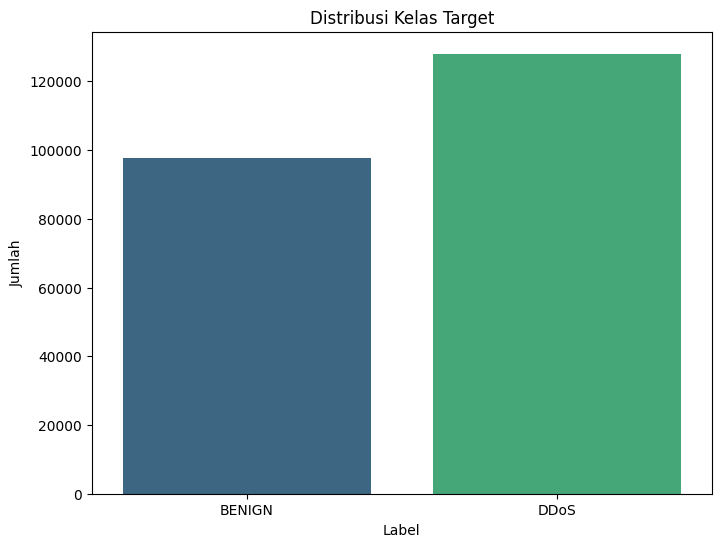

In [438]:
# Visualisasi distribusi kolom target 'Label'
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Label', palette='viridis')
plt.title('Distribusi Kelas Target')
plt.ylabel('Jumlah')
plt.show()

In [439]:
print("Data duplikat: ", df.duplicated().sum())

Data duplikat:  2633


In [440]:
print("Data missing: ", df.isnull().sum().sum())

Data missing:  4


In [441]:
df.nunique()

Destination Port                23950
Flow Duration                  187752
Total Fwd Packets                 297
Total Backward Packets            367
Total Length of Fwd Packets      3831
Total Length of Bwd Packets      6760
Fwd Packet Length Max            1891
Fwd Packet Length Min             151
Fwd Packet Length Mean           7401
Fwd Packet Length Std            9555
Bwd Packet Length Max            1945
Bwd Packet Length Min             343
Bwd Packet Length Mean           8655
Bwd Packet Length Std            9650
Flow Bytes/s                   202293
Flow Packets/s                 194094
Flow IAT Mean                  193666
Flow IAT Std                   159622
Flow IAT Max                   139745
Flow IAT Min                    11093
Fwd IAT Total                   78049
Fwd IAT Mean                    95095
Fwd IAT Std                     91184
Fwd IAT Max                     77978
Fwd IAT Min                      8820
Bwd IAT Total                  101942
Bwd IAT Mean

In [442]:
# Mengecek apakah ada nilai tak hingga (infinity) dalam DataFrame
np.isinf(df.select_dtypes(include=np.number)).sum()

Destination Port                0
Flow Duration                   0
Total Fwd Packets               0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Fwd Packet Length Max           0
Fwd Packet Length Min           0
Fwd Packet Length Mean          0
Fwd Packet Length Std           0
Bwd Packet Length Max           0
Bwd Packet Length Min           0
Bwd Packet Length Mean          0
Bwd Packet Length Std           0
Flow Bytes/s                   30
Flow Packets/s                 34
Flow IAT Mean                   0
Flow IAT Std                    0
Flow IAT Max                    0
Flow IAT Min                    0
Fwd IAT Total                   0
Fwd IAT Mean                    0
Fwd IAT Std                     0
Fwd IAT Max                     0
Fwd IAT Min                     0
Bwd IAT Total                   0
Bwd IAT Mean                    0
Bwd IAT Std                     0
Bwd IAT Max                     0
Bwd IAT Min   

# 3. Data Preprocessing & Feature Engineering

## 3.1 Data Cleaning

In [443]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("Data duplikat setelah penghapusan: ", df.duplicated().sum())

Data duplikat setelah penghapusan:  0


In [444]:
# Mengganti nilai tak hingga (infinity) dengan NaN
kolom_numerik = df.select_dtypes(include=[np.number]).columns
df[kolom_numerik] = df[kolom_numerik].replace([np.inf, -np.inf], np.nan)
print("Jumlah nilai NaN setelah penggantian: ", df.isnull().sum().sum())

Jumlah nilai NaN setelah penggantian:  60


In [445]:
# Inputasi nilai NaN dengan median kolom
df[kolom_numerik] = df[kolom_numerik].fillna(df[kolom_numerik].median())
print("Jumlah nilai NaN setelah inputasi: ", df.isnull().sum().sum())

Jumlah nilai NaN setelah inputasi:  0


## 3.2 Split Data

In [446]:
# MEMBAGI DATA FRAME SECARA UTUH (80% Train, 20% Test)
# Parameter stratify=df['Label'] adalah kunci agar proporsinya setara
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['Label'])

# Melihat hasil pembagian
print("=== Ukuran DataFrame ===")
print(f"Total baris awal  : {df.shape[0]}")
print(f"Baris df_train    : {df_train.shape[0]} (80%)")
print(f"Baris df_test     : {df_test.shape[0]} (20%)")

print("\n=== Proporsi Label di df_train ===")
print(df_train['Label'].value_counts(normalize=True) * 100)

print("\n=== Proporsi Label di df_test ===")
print(df_test['Label'].value_counts(normalize=True) * 100)

=== Ukuran DataFrame ===
Total baris awal  : 223112
Baris df_train    : 178489 (80%)
Baris df_test     : 44623 (20%)

=== Proporsi Label di df_train ===
Label
DDoS      57.377205
BENIGN    42.622795
Name: proportion, dtype: float64

=== Proporsi Label di df_test ===
Label
DDoS      57.378482
BENIGN    42.621518
Name: proportion, dtype: float64


## 3.3 Feature Selection

In [447]:
X_train = df_train.drop(columns=['Label']).select_dtypes(include=[np.number])
y_train = df_train['Label']
y_train_encoded = LabelEncoder().fit_transform(y_train)

In [448]:
var_filter = VarianceThreshold(threshold=3)
var_filter.fit(X_train)
survived_cols = X_train.columns[var_filter.get_support()]
X_train_var = X_train[survived_cols]
print(f"Fitur setelah variance filter: {len(survived_cols)}")

Fitur setelah variance filter: 59


In [449]:
# =========================================================
# TAHAP 2: Information Gain
# =========================================================
def entropy_bits(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def info_gain(x, y, n_bins=10, ratio=False):
    # diskretisasi equal-frequency, lalu hitung IG = H(Y) - H(Y|A)
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1))[1:-1])
    a = np.searchsorted(edges, x, side='left')
    joint = np.zeros((a.max() + 1, y.max() + 1))
    np.add.at(joint, (a, y), 1)
    h_y = entropy_bits(joint.sum(axis=0))
    n = joint.sum()
    h_y_a = sum(r.sum() / n * entropy_bits(r) for r in joint if r.sum() > 0)
    ig = h_y - h_y_a
    if ratio:  # Information Gain Ratio (rumus 2 di paper)
        h_a = entropy_bits(joint.sum(axis=1))
        return ig / h_a if h_a > 0 else 0.0
    return ig

ig_scores = [info_gain(X_train_var[c].values, y_train_encoded) for c in survived_cols]

In [450]:
ig_df = pd.DataFrame({'Feature': survived_cols, 'Weight': ig_scores})
ig_df = ig_df.sort_values(by='Weight', ascending=False)

top_features = ig_df[ig_df['Weight'] > 0.6]['Feature'].tolist()
print(f"Jumlah fitur terpilih: {len(top_features)}")
for i, f in enumerate(top_features, 1):
    print(f"{i}. {f}")

Jumlah fitur terpilih: 11
1. Destination Port
2. Total Length of Fwd Packets
3. Subflow Fwd Bytes
4. Bwd Packet Length Max
5. Bwd Packet Length Mean
6. Avg Bwd Segment Size
7. Total Length of Bwd Packets
8. Subflow Bwd Bytes
9. Fwd Packet Length Max
10. Avg Fwd Segment Size
11. Fwd Packet Length Mean


In [451]:
df_train = df_train[top_features + ['Label']]
df_test  = df_test[top_features + ['Label']]

print(df_train.shape, df_test.shape)

(178489, 12) (44623, 12)
